# 02 — Dimensionality Reduction & Fisher's Criterion Verification (Part 2)

This notebook verifies our **from-scratch NumPy implementations** in `src/reduction/` (`StandardScaler`, `PCA`, `LDA`, and `fisher_score`) against `scikit-learn` using the Part 1 feature extraction (`extract_features`) and corruption (`corrupt`, `mean_impute`) pipeline.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler as SKScaler
from sklearn.decomposition import PCA as SKPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as SKLDA
from sklearn.neighbors import KNeighborsClassifier

from src import config as C
from src.data.load import load_raw
from src.data.features import extract_features, feature_names
from src.data.corrupt import corrupt, mean_impute
from src.reduction.scaler import StandardScaler
from src.reduction.pca import PCA
from src.reduction.lda import LDA
from src.reduction.fisher import scatter_matrices, fisher_score

np.random.seed(C.SEED)

## 1. Load Raw Signals & Extract Part 1 Features
Uses `load_raw()` and `extract_features()` from Part 1 (`src/data/`).

In [2]:
X_raw, y, subjects = load_raw(C.DATA_DIR)
X = extract_features(X_raw)
names = feature_names()
print(f'Raw windows: {X_raw.shape} -> Extracted features: {X.shape} ({len(names)} feature names)')

Raw windows: (10299, 128, 9) -> Extracted features: (10299, 63) (63 feature names)


## 2. Numerical Verification vs. `scikit-learn`

In [3]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled_sk = SKScaler().fit_transform(X)
print('Max abs diff (StandardScaler vs sklearn):', np.max(np.abs(X_scaled - X_scaled_sk)))

pca_ours = PCA(var=C.PCA_VAR).fit(X_scaled)
pca_sk = SKPCA(n_components=C.PCA_VAR).fit(X_scaled)
Z_pca = pca_ours.transform(X_scaled)
Z_pca_sk = pca_sk.transform(X_scaled)
print(f'PCA components retained (95% var): ours={pca_ours.n_components_}, sklearn={pca_sk.n_components_}')
print('Max abs diff in explained_variance_ratio_:', np.max(np.abs(pca_ours.explained_variance_ratio_ - pca_sk.explained_variance_ratio_)))
print('Max abs diff in |Z_pca| projection:', np.max(np.abs(np.abs(Z_pca) - np.abs(Z_pca_sk))))

lda_ours = LDA(n_components=C.LDA_DIMS).fit(X_scaled, y)
lda_sk = SKLDA(n_components=C.LDA_DIMS).fit(X_scaled, y)
Z_lda = lda_ours.transform(X_scaled)
Z_lda_sk = lda_sk.transform(X_scaled)
acc_ours = KNeighborsClassifier(5).fit(Z_lda, y).score(Z_lda, y)
acc_sk = KNeighborsClassifier(5).fit(Z_lda_sk, y).score(Z_lda_sk, y)
print(f'Downstream 5-NN accuracy on LDA embedding: ours={acc_ours:.4f}, sklearn={acc_sk:.4f}')
print(f"Fisher's Criterion J = trace(S_B)/trace(S_W): Raw={fisher_score(X_scaled, y):.3f} | PCA={fisher_score(Z_pca, y):.3f} | LDA={fisher_score(Z_lda, y):.3f}")

Max abs diff (StandardScaler vs sklearn): 0.0
PCA components retained (95% var): ours=25, sklearn=25
Max abs diff in explained_variance_ratio_: 2.220446049250313e-16
Max abs diff in |Z_pca| projection: 5.520028878436278e-13
Downstream 5-NN accuracy on LDA embedding: ours=0.9452, sklearn=0.9471
Fisher's Criterion J = trace(S_B)/trace(S_W): Raw=1.023 | PCA=1.125 | LDA=17.790


## 3. PCA Scree Plot & Fisher's Criterion Across All 3 Part-1 Corruption Modes (`0% → 50%`)

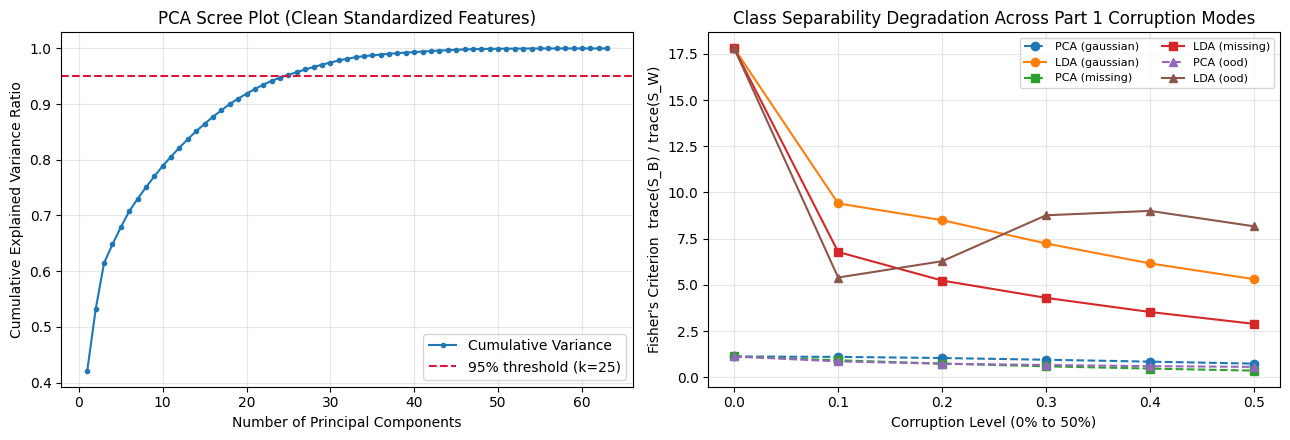

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: PCA Cumulative Explained Variance
cum_var = np.cumsum(pca_ours.all_explained_variance_ratio_)
axes[0].plot(np.arange(1, len(cum_var) + 1), cum_var, marker='o', markersize=3, label='Cumulative Variance')
axes[0].axhline(C.PCA_VAR, color='crimson', linestyle='--', label=f'{int(C.PCA_VAR*100)}% threshold (k={pca_ours.n_components_})')
axes[0].set_xlabel('Number of Principal Components')
axes[0].set_ylabel('Cumulative Explained Variance Ratio')
axes[0].set_title('PCA Scree Plot (Clean Standardized Features)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: Fisher's Criterion vs Corruption Level using Part 1's corrupt() and mean_impute()
for kind, marker in zip(C.KINDS, ['o', 's', '^']):
    j_pca, j_lda = [], []
    for lvl in C.LEVELS:
        X_corr = corrupt(X, X_raw, kind=kind, level=lvl, seed=C.SEED)
        if kind == 'missing':
            X_corr, _ = mean_impute(X_corr, X_corr)
        Xs = StandardScaler().fit_transform(X_corr)
        j_pca.append(fisher_score(PCA(C.PCA_VAR).fit_transform(Xs), y))
        j_lda.append(fisher_score(LDA(C.LDA_DIMS).fit_transform(Xs, y), y))
    axes[1].plot(C.LEVELS, j_pca, f'{marker}--', label=f'PCA ({kind})')
    axes[1].plot(C.LEVELS, j_lda, f'{marker}-', label=f'LDA ({kind})')

axes[1].set_xlabel('Corruption Level (0% to 50%)')
axes[1].set_ylabel("Fisher's Criterion  trace(S_B) / trace(S_W)")
axes[1].set_title("Class Separability Degradation Across Part 1 Corruption Modes")
axes[1].legend(fontsize=8, ncol=2)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. 2D Projection Comparison: PCA vs. LDA (Clean vs. 50% Gaussian Noise)

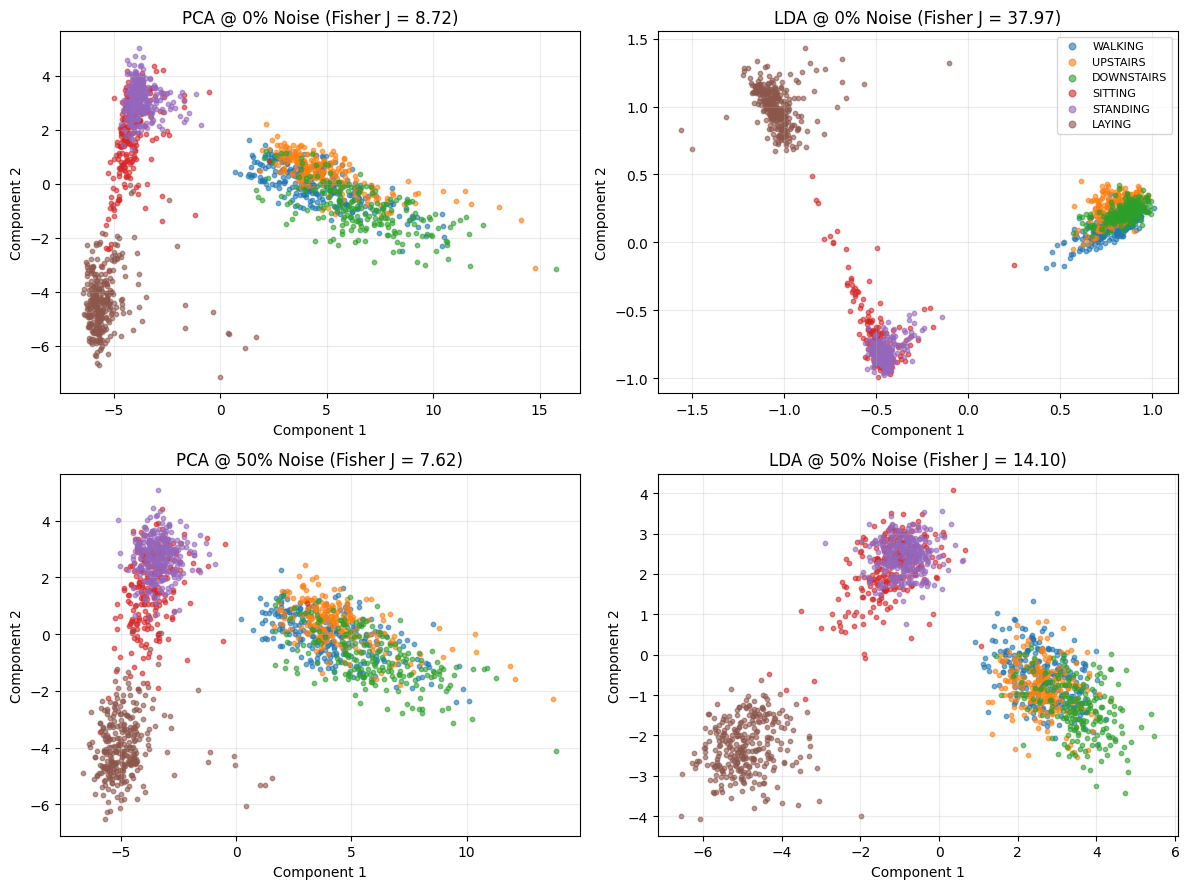

In [5]:
idx = np.random.default_rng(C.SEED).choice(len(y), size=1500, replace=False)
X_noisy50 = corrupt(X, X_raw, kind='gaussian', level=0.5, seed=C.SEED)
Xs_clean = StandardScaler().fit_transform(X)
Xs_noisy = StandardScaler().fit_transform(X_noisy50)

embeddings = [
    ('PCA @ 0% Noise', PCA(2).fit_transform(Xs_clean)),
    ('LDA @ 0% Noise', LDA(2).fit_transform(Xs_clean, y)),
    ('PCA @ 50% Noise', PCA(2).fit_transform(Xs_noisy)),
    ('LDA @ 50% Noise', LDA(2).fit_transform(Xs_noisy, y)),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (title, Z) in zip(axes.ravel(), embeddings):
    for c, name in enumerate(C.ACTIVITIES):
        m = y[idx] == c
        ax.scatter(Z[idx][m, 0], Z[idx][m, 1], s=10, alpha=0.6, label=name)
    ax.set_title(f'{title} (Fisher J = {fisher_score(Z, y):.2f})')
    ax.set_xlabel('Component 1'); ax.set_ylabel('Component 2')
    ax.grid(alpha=0.25)
axes[0, 1].legend(loc='upper right', fontsize=8, markerscale=1.5)
plt.tight_layout()
plt.show()